<a href="https://colab.research.google.com/github/kzlnyi/ML/blob/main/%22%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%9C%D0%9D_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D0%B8%D1%85_%D1%80%D1%8F%D0%B4%D1%96%D0%B2_%D0%93%D0%BE%D0%BB%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_3_12_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум: аналіз і прогнозування часових рядів

Цей notebook доповнює лекцію **«Аналіз і прогнозування часових рядів. Навчання та оцінка моделі»**.

Мета практикуму — послідовно пройти основні етапи прогнозування:

1. підготовка часових даних;
2. візуальний аналіз;
3. дослідження тренду та сезонності;
4. коректний часовий поділ на train/test;
5. побудова базових прогнозів;
6. оцінювання якості за MAE, RMSE, sMAPE та MASE;
7. застосування ETS;
8. застосування SARIMA;
9. використання Prophet;
10. побудова ML-моделі на лагових і календарних ознаках;
11. покрокова ретроспективна перевірка;
12. самостійні завдання.

**Важливо:** у часових рядах не можна випадково перемішувати спостереження перед поділом на навчальну і тестову вибірки.

## 1. Підключення бібліотек

In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2. Формування навчального часового ряду

Щоб notebook можна було виконувати без завантаження зовнішніх файлів, використаємо штучно сформований щоденний ряд продажів. Він містить:

- довгостроковий тренд;
- тижневу сезонність;
- річну сезонність;
- підвищення попиту у вихідні;
- випадковий шум;
- декілька аномальних значень.

Такий ряд зручний для демонстрації основних етапів forecasting.

In [7]:
dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
n = len(dates)
t = np.arange(n)

trend = 100 + 0.035 * t
weekly = 12 * np.sin(2 * np.pi * t / 7)
yearly = 8 * np.sin(2 * np.pi * t / 365.25)
weekend = np.where(dates.dayofweek >= 5, 10, 0)
noise = np.random.normal(0, 6, n)

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({
    "date": dates,
    "sales": sales
})

# Додаємо кілька пропусків та аномалій для демонстрації підготовки даних
missing_idx = [120, 450, 900]
outlier_idx = [300, 700, 1100]

df.loc[missing_idx, "sales"] = np.nan
df.loc[outlier_idx, "sales"] *= 1.7

df.head()

,date,sales
0,2022-01-01,112.980285
1,2022-01-02,118.725005
2,2022-01-03,115.930451
3,2022-01-04,114.862459
4,2022-01-05,94.078518


In [8]:
print(df.shape)
print(df.dtypes)
print("\nКількість пропусків:")
print(df.isna().sum())

(1461, 2)
date     datetime64[ns]
sales           float64
dtype: object

Кількість пропусків:
date     0
sales    3
dtype: int64


### Завдання 1. Первинний аналіз

1. Виведіть останні 10 рядків.
2. Визначте мінімальну та максимальну дату.
3. Обчисліть середнє, медіану, стандартне відхилення, мінімум і максимум `sales`.
4. Перевірте, чи є дублікати дат.

In [9]:
print("Останні 10 рядків:")
print(df.tail(10))
print("\nМінімальна дата:", df["date"].min().date())
print("Максимальна дата:", df["date"].max().date())
print("\nСтатистика продажів:")
print(df["sales"].agg(["mean", "median", "std", "min", "max"]).round(2))
print("\nКількість дублікатів дат:", df["date"].duplicated().sum())

Останні 10 рядків:
           date       sales
1451 2025-12-22  171.328008
1452 2025-12-23  156.237492
1453 2025-12-24  160.161011
1454 2025-12-25  141.622914
1455 2025-12-26  130.154195
1456 2025-12-27  164.792801
1457 2025-12-28  172.113885
1458 2025-12-29  170.054977
1459 2025-12-30  160.035508
1460 2025-12-31  144.925047

Мінімальна дата: 2022-01-01
Максимальна дата: 2025-12-31

Статистика продажів:
mean      128.87
median    128.31
std        19.97
min        78.05
max       279.57
Name: sales, dtype: float64

Кількість дублікатів дат: 0


## 3. Підготовка часових даних

Для подальшого аналізу необхідно:

- перетворити дату у формат `datetime`;
- відсортувати дані;
- зробити дату індексом;
- перевірити регулярність часового кроку;
- обробити пропущені значення.

У цьому прикладі пропуски заповнюються часовою інтерполяцією.

In [10]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

D
Пропусків після інтерполяції: 0


,sales
date,
2022-01-01,112.980285
2022-01-02,118.725005
2022-01-03,115.930451
2022-01-04,114.862459
2022-01-05,94.078518


### Завдання 2. Робота з пропусками

Створіть копію набору даних `df_task` і штучно видаліть значення `sales` для п'яти довільних дат.

Порівняйте три способи заповнення:

- `ffill`;
- лінійну інтерполяцію;
- часову інтерполяцію.

Коротко поясніть, який спосіб доцільніший для цього ряду.

In [11]:
df_task = df.copy()
missing_dates = df_task.index[[50, 150, 320, 550, 800]]
original = df_task.loc[missing_dates, "sales"].copy()
df_task.loc[missing_dates, "sales"] = np.nan

df_task["ffill"] = df_task["sales"].ffill()
df_task["linear"] = df_task["sales"].interpolate(method="linear")
df_task["time"] = df_task["sales"].interpolate(method="time")

check_missing = df_task.loc[missing_dates, ["ffill", "linear", "time"]].copy()
check_missing.insert(0, "Справжнє значення", original)
print(check_missing.round(2))
for method in ["ffill", "linear", "time"]:
    error = mean_absolute_error(original, df_task.loc[missing_dates, method])
    print("MAE", method, ":", round(error, 2))
print("Висновок: для щоденних рівномірних даних лінійна та часова")
print("інтерполяції збігаються, а ffill переносить останнє значення.")

            Справжнє значення   ffill  linear    time
date                                                 
2022-02-20             129.14  107.11  112.22  112.22
2022-05-31             116.22  123.07  114.68  114.68
2022-11-17              94.47   99.46   99.68   99.68
2023-07-05             114.27  120.64  113.43  113.43
2024-03-11             152.77  154.92  146.28  146.28
MAE ffill : 8.48
MAE linear : 6.2
MAE time : 6.2
Висновок: для щоденних рівномірних даних лінійна та часова
інтерполяції збігаються, а ffill переносить останнє значення.


## 4. Візуальний аналіз

Графік часового ряду є першим інструментом діагностики. За ним оцінюють:

- загальний напрям зміни;
- сезонні коливання;
- можливі структурні зміни;
- викиди;
- зміну дисперсії.

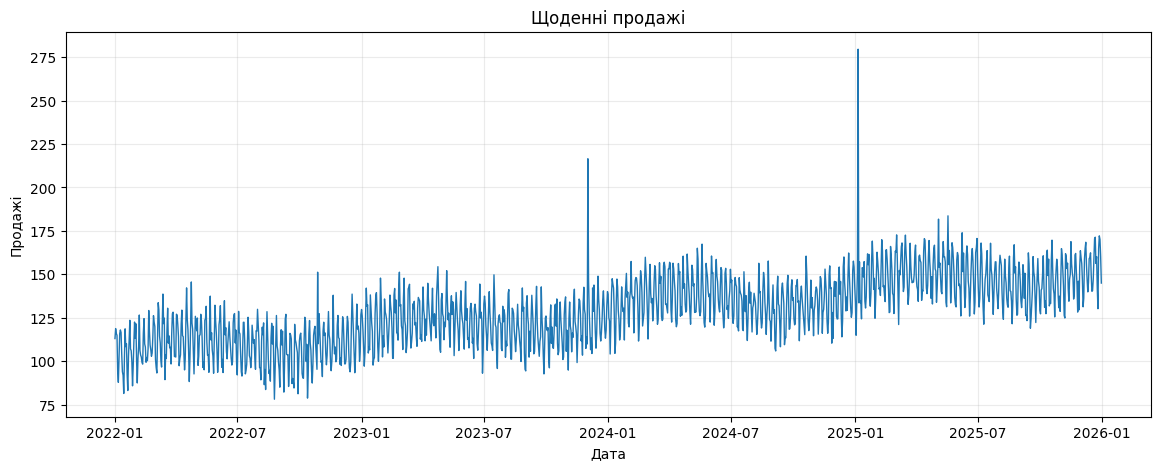

In [12]:
, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

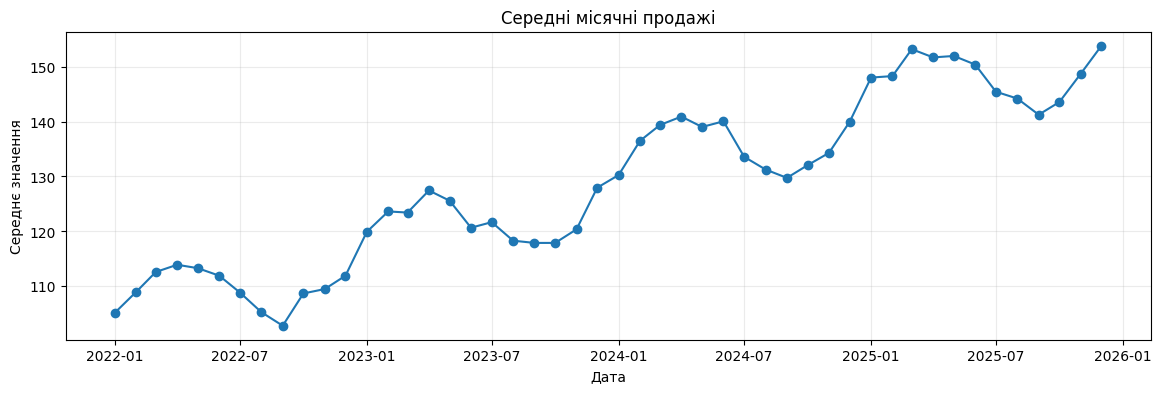

In [13]:
monthly = df["sales"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Середні місячні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

### Завдання 3. Візуалізація

1. Побудуйте графік останніх 90 днів.
2. Побудуйте 7-денне та 30-денне ковзні середні.
3. Поясніть, чим відрізняється інформація на цих двох графіках.

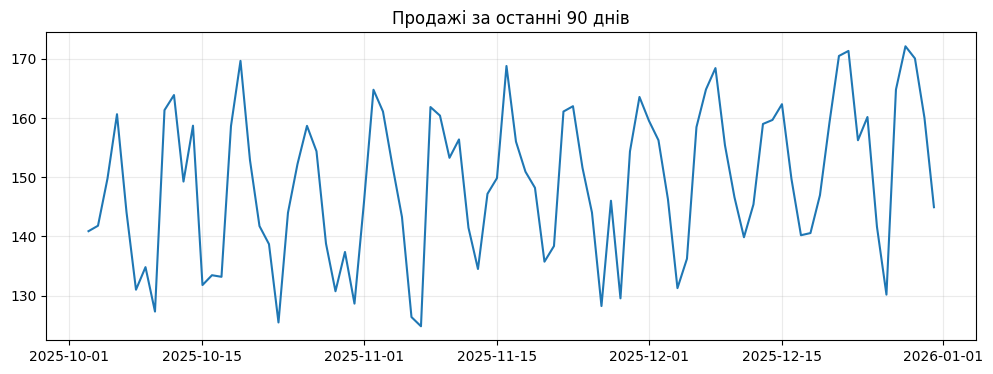

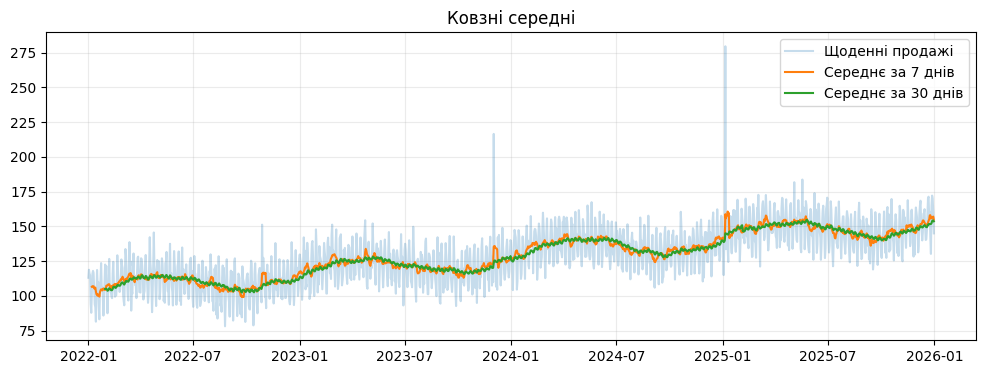

7-денне середнє краще показує короткі зміни, а 30-денне
сильніше згладжує коливання та показує загальний тренд.


In [14]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index[-90:], df["sales"].iloc[-90:])
ax.set_title("Продажі за останні 90 днів")
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df["sales"], alpha=0.25, label="Щоденні продажі")
ax.plot(df.index, df["sales"].rolling(7).mean(), label="Середнє за 7 днів")
ax.plot(df.index, df["sales"].rolling(30).mean(), label="Середнє за 30 днів")
ax.set_title("Ковзні середні")
ax.legend()
ax.grid(alpha=0.25)
plt.show()
print("7-денне середнє краще показує короткі зміни, а 30-денне")
print("сильніше згладжує коливання та показує загальний тренд.")

## 5. Декомпозиція ряду методом STL

STL-декомпозиція розкладає часовий ряд на:

- **trend** — довгострокову тенденцію;
- **seasonal** — сезонну складову;
- **resid** — залишкову складову.

Для щоденних даних з тижневою сезонністю використаємо `period=7`.

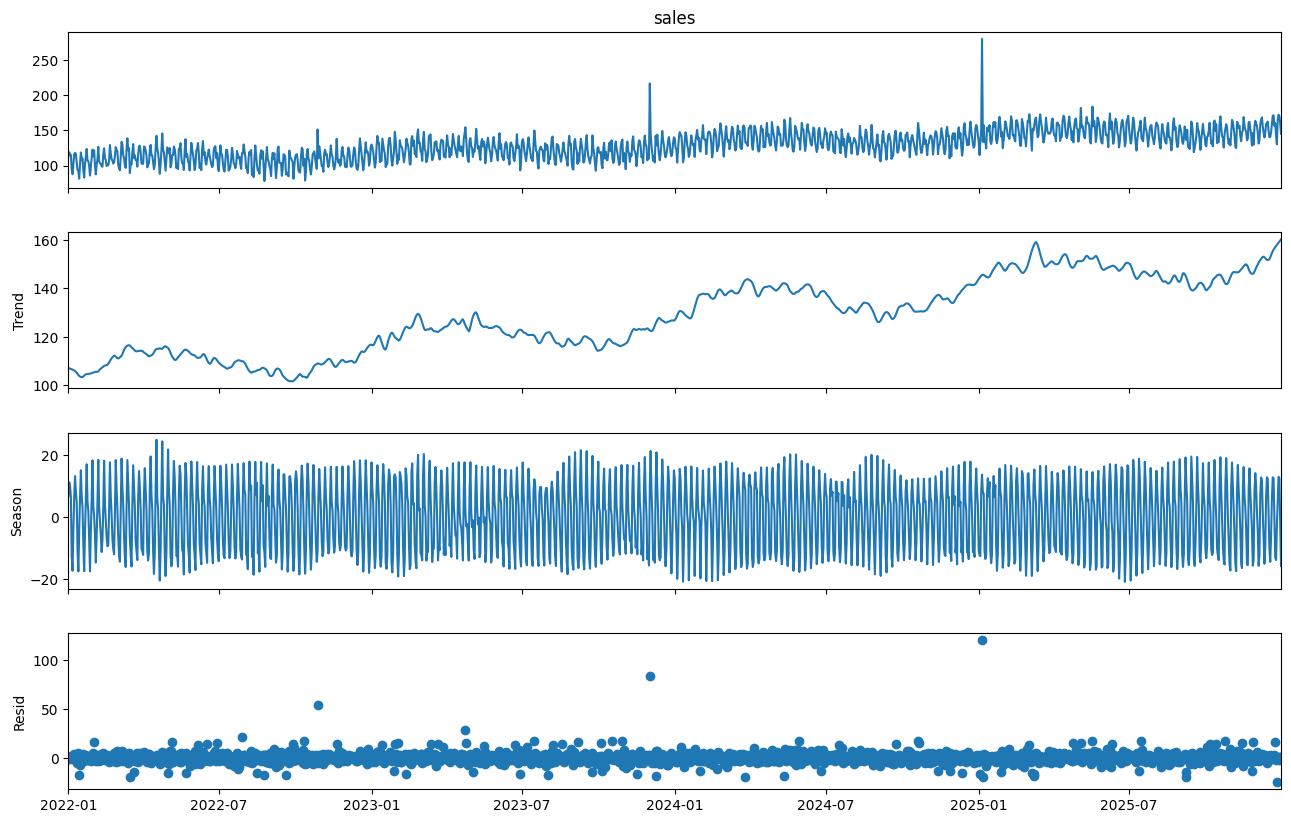

In [15]:
stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.show()

### Завдання 4. Декомпозиція

1. Повторіть STL-декомпозицію для місячного ряду.
2. Оберіть обґрунтований період сезонності.
3. Проаналізуйте тренд та залишки.

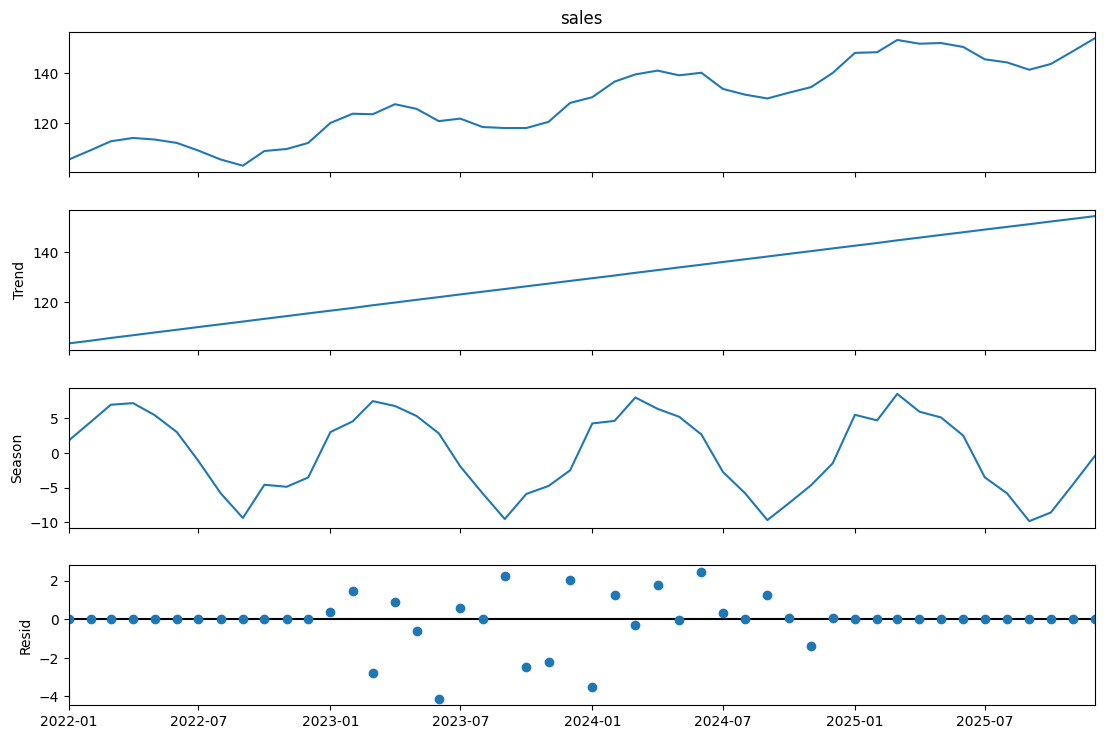

Період сезонності — 12 місяців (один рік).
Тренд на початку: 103.48
Тренд наприкінці: 154.31
Стандартне відхилення залишків: 1.27
Тренд зростає. Залишки — це випадкові коливання та можливі аномалії.


In [16]:
monthly_stl = STL(monthly, period=12, robust=True).fit()
fig = monthly_stl.plot()
fig.set_size_inches(12, 8)
plt.show()
print("Період сезонності — 12 місяців (один рік).")
print("Тренд на початку:", round(monthly_stl.trend.iloc[0], 2))
print("Тренд наприкінці:", round(monthly_stl.trend.iloc[-1], 2))
print("Стандартне відхилення залишків:", round(monthly_stl.resid.std(), 2))
print("Тренд зростає. Залишки — це випадкові коливання та можливі аномалії.")

## 6. Часовий поділ train/test

У звичайних задачах машинного навчання дані часто перемішують. Для часових рядів це зазвичай неприпустимо.

Нехай останні 90 днів становлять тестовий період. Усі попередні спостереження використовуються для навчання.

In [17]:
horizon = 90

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Train:", train.index.min().date(), "—", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "—", test.index.max().date(), len(test))

Train: 2022-01-01 — 2025-10-02 1371
Test : 2025-10-03 — 2025-12-31 90


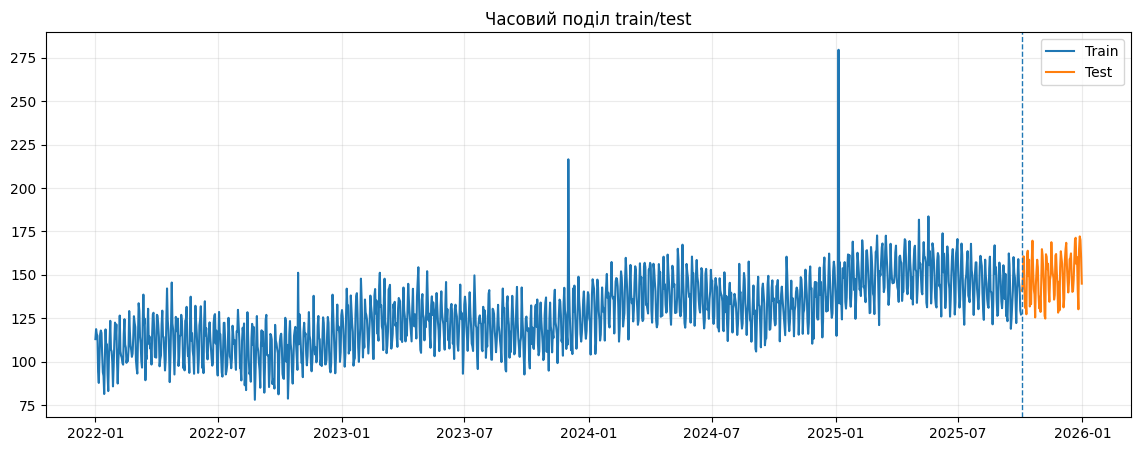

In [18]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

### Завдання 5. Часовий поділ

Створіть інший варіант поділу, у якому тестовий період дорівнює 60 дням.

Виведіть:

- кількість спостережень у train;
- кількість спостережень у test;
- останню дату train;
- першу дату test.

In [19]:
train_60 = df.iloc[:-60]
test_60 = df.iloc[-60:]
print("Train:", len(train_60), "спостережень")
print("Test:", len(test_60), "спостережень")
print("Остання дата train:", train_60.index.max().date())
print("Перша дата test:", test_60.index.min().date())

Train: 1401 спостережень
Test: 60 спостережень
Остання дата train: 2025-11-01
Перша дата test: 2025-11-02


## 7. Базові моделі прогнозування

Перед використанням складної моделі потрібно побудувати простий базовий прогноз.

### Naive forecast
Прогноз дорівнює останньому відомому значенню.

### Seasonal naive
Прогноз повторює значення попереднього сезонного циклу. Для щоденних даних з тижневою сезонністю використаємо лаг 7.

In [20]:
naive_pred = np.repeat(train["sales"].iloc[-1], len(test))

history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

baseline = pd.DataFrame({
    "actual": test["sales"].values,
    "naive": naive_pred,
    "seasonal_naive": seasonal_naive_pred
}, index=test.index)

baseline.head()

,actual,naive,seasonal_naive
date,,,
2025-10-03,140.875312,127.213304,137.575710
2025-10-04,141.794922,127.213304,148.849817
2025-10-05,149.768594,127.213304,159.044241
2025-10-06,160.638161,127.213304,145.953075
2025-10-07,144.109047,127.213304,142.430282


## 8. Метрики якості прогнозу

Використаємо:

- **MAE** — середню абсолютну помилку;
- **RMSE** — квадратний корінь із середньоквадратичної помилки;
- **sMAPE** — симетричну відносну помилку;
- **MASE** — масштабовану абсолютну помилку.

Менше значення метрики зазвичай означає кращий прогноз.

In [21]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred))
    mask = denom != 0
    return 100 * np.mean(
        2 * np.abs(y_pred[mask] - y_true[mask]) / denom[mask]
    )

def mase(y_true, y_pred, y_train, seasonality=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )
    return np.mean(np.abs(y_true - y_pred)) / scale

def evaluate(y_true, y_pred, y_train, seasonality=7):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE_%": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonality)
    }

results = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)
}).T

results

,MAE,RMSE,sMAPE_%,MASE
Naive,22.039691,25.297086,15.570350,3.108885
Seasonal naive,7.734062,9.380056,5.276847,1.090955


### Завдання 6. Метрики

1. Визначте, яка базова модель є кращою.
2. Поясніть, чому висновок не слід робити лише за однією метрикою.
3. Обчисліть MAE окремо для перших і останніх 30 днів тестового періоду.

In [22]:
print("Порівняння базових моделей:")
print(results.round(2))
print("Краща модель за MAE:", results["MAE"].idxmin())

for name, pred in [("Naive", naive_pred), ("Seasonal naive", seasonal_naive_pred)]:
    first_mae = mean_absolute_error(test["sales"].iloc[:30], pred[:30])
    last_mae = mean_absolute_error(test["sales"].iloc[-30:], pred[-30:])
    print(name, "— MAE перших 30:", round(first_mae, 2),
          "; останніх 30:", round(last_mae, 2))
print("Одна метрика не описує всі помилки: RMSE сильніше враховує великі")
print("відхилення, а sMAPE та MASE дають інше уявлення про похибку.")
print("У готовому прикладі seasonal naive використовує значення з test:")
print("це оцінка з відомими попередніми днями, а не чесний прогноз на 90 днів.")

Порівняння базових моделей:
                  MAE   RMSE  sMAPE_%  MASE
Naive           22.04  25.30    15.57  3.11
Seasonal naive   7.73   9.38     5.28  1.09
Краща модель за MAE: Seasonal naive
Naive — MAE перших 30: 17.55 ; останніх 30: 26.4
Seasonal naive — MAE перших 30: 8.16 ; останніх 30: 6.77
Одна метрика не описує всі помилки: RMSE сильніше враховує великі
відхилення, а sMAPE та MASE дають інше уявлення про похибку.
У готовому прикладі seasonal naive використовує значення з test:
це оцінка з відомими попередніми днями, а не чесний прогноз на 90 днів.


## 9. Експоненційне згладжування ETS

Моделі ETS описують часовий ряд через рівень, тренд і сезонність.

Для навчального прикладу використаємо:

- адитивний тренд;
- адитивну сезонність;
- сезонний період 7 днів.

In [23]:
ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred = ets_model.forecast(len(test))

ets_metrics = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

ets_metrics

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


{'MAE': 13.11452610803631,
 'RMSE': np.float64(15.229020700077848),
 'sMAPE_%': np.float64(9.14961742586639),
 'MASE': np.float64(1.8499146745742305)}

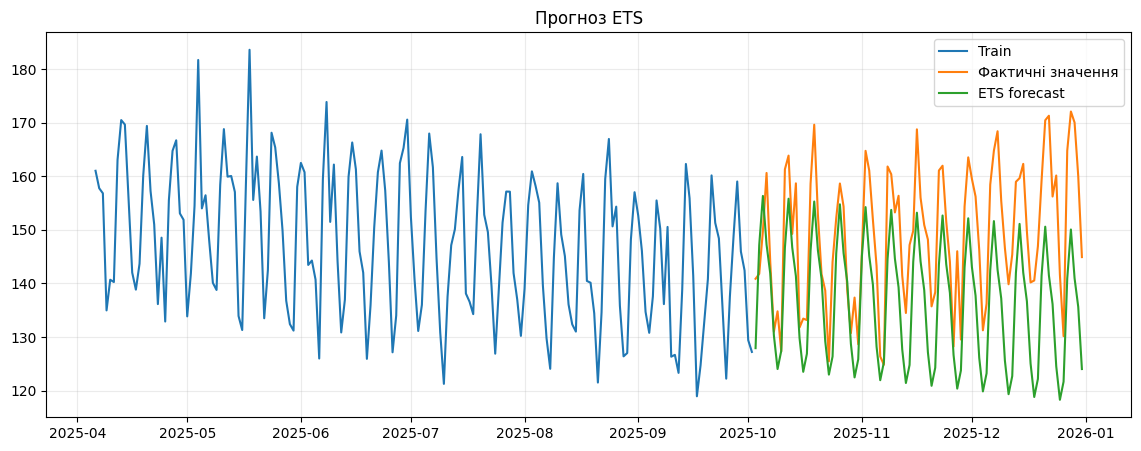

In [24]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

### Завдання 7. ETS

1. Побудуйте ETS-модель без тренду.
2. Порівняйте її з поточною моделлю.
3. Додайте результати обох ETS-моделей до таблиці метрик.

In [25]:
ets_no_trend = ExponentialSmoothing(
    train["sales"],
    trend=None,
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_no_trend_pred = ets_no_trend.forecast(len(test))
ets_no_trend_metrics = evaluate(test["sales"], ets_no_trend_pred, train["sales"], 7)
ets_compare = pd.DataFrame({"ETS з трендом": ets_metrics,
                            "ETS без тренду": ets_no_trend_metrics}).T
print(ets_compare.round(2))
print("Краща ETS за MAE:", ets_compare["MAE"].idxmin())

                  MAE   RMSE  sMAPE_%  MASE
ETS з трендом   13.11  15.23     9.15  1.85
ETS без тренду   8.89  10.70     6.09  1.25
Краща ETS за MAE: ETS без тренду


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


## 10. SARIMA

SARIMA розширює ARIMA сезонними компонентами.

У загальному випадку модель записують як:

**SARIMA(p, d, q)(P, D, Q, s)**,

де `s` — довжина сезонного циклу.

Нижче використано невелику модель, щоб приклад виконувався відносно швидко.

In [26]:
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

sarima_metrics = evaluate(
    test["sales"],
    sarima_pred,
    train["sales"],
    seasonality=7
)

sarima_metrics

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


{'MAE': 7.7465658208202095,
 'RMSE': np.float64(9.401756189500011),
 'sMAPE_%': np.float64(5.302245527656123),
 'MASE': np.float64(1.0927185375542505)}

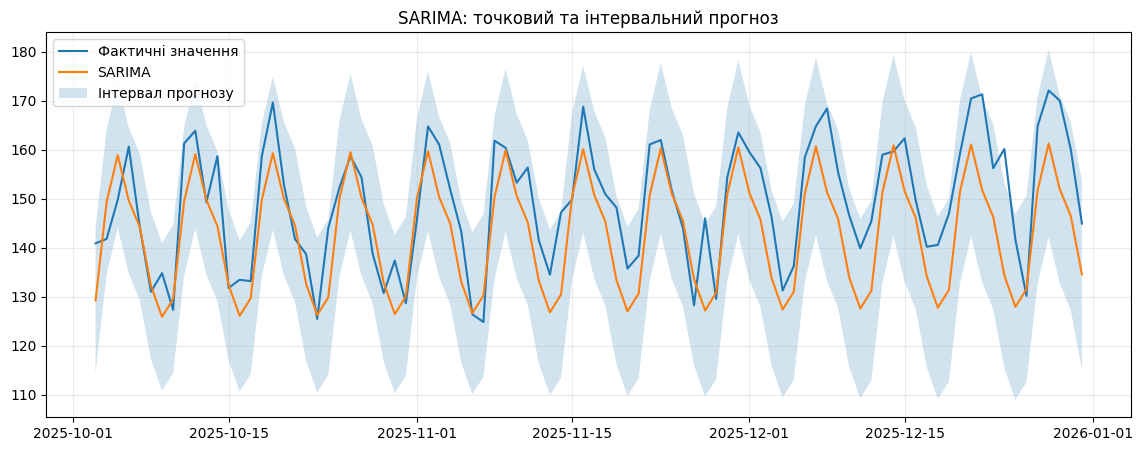

In [27]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

### Завдання 8. SARIMA

Змініть параметри моделі, наприклад:

- `order=(2, 1, 1)`;
- `seasonal_order=(1, 1, 0, 7)`.

Порівняйте MAE та RMSE з попередньою SARIMA-моделлю.

**Примітка:** мета завдання — зрозуміти вплив параметрів, а не виконати повний автоматичний підбір.

In [28]:
sarima_alt_model = SARIMAX(
    train["sales"],
    order=(2, 1, 1),
    seasonal_order=(1, 1, 0, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=80)

sarima_alt_pred = sarima_alt_model.forecast(steps=len(test))
sarima_alt_metrics = evaluate(test["sales"], sarima_alt_pred, train["sales"], 7)
sarima_compare = pd.DataFrame({"SARIMA початкова": sarima_metrics,
                               "SARIMA змінена": sarima_alt_metrics}).T
print(sarima_compare[["MAE", "RMSE"]].round(2))
print("Краща SARIMA за MAE:", sarima_compare["MAE"].idxmin())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                   MAE  RMSE
SARIMA початкова  7.75  9.40
SARIMA змінена    8.09  9.66
Краща SARIMA за MAE: SARIMA початкова


## 11. Prophet

Prophet зручно використовувати для рядів з трендом, сезонністю та календарними ефектами.

У Prophet назви основних стовпців мають бути:

- `ds` — дата;
- `y` — цільове значення.

Якщо бібліотека не встановлена, у Google Colab її можна встановити командою:

```python
!pip -q install prophet
```

In [29]:
!pip -q install prophet

In [53]:
from prophet import Prophet

prophet_train = (
    train.reset_index()
         .rename(columns={"date": "ds", "sales": "y"})
)

model_prophet = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)

model_prophet.fit(prophet_train)

future = model_prophet.make_future_dataframe(
    periods=len(test),
    freq="D"
)

forecast = model_prophet.predict(future)

prophet_pred = (
    forecast.set_index("ds")
            .loc[test.index, "yhat"]
)

evaluate(
    test["sales"],
    prophet_pred,
    train["sales"],
    seasonality=7
)

{'MAE': 5.3019589947018195,
 'RMSE': np.float64(6.4375131479292),
 'sMAPE_%': np.float64(3.619983187399482),
 'MASE': np.float64(0.7478860972551259)}

### Завдання 9. Prophet

Після встановлення `prophet`:

1. навчіть модель;
2. отримайте прогноз на тестовий період;
3. побудуйте графік;
4. виведіть компоненти моделі;
5. порівняйте MAE з ETS та SARIMA.

Порівняння MAE:
Prophet: 5.3
ETS: 13.11
SARIMA: 7.75


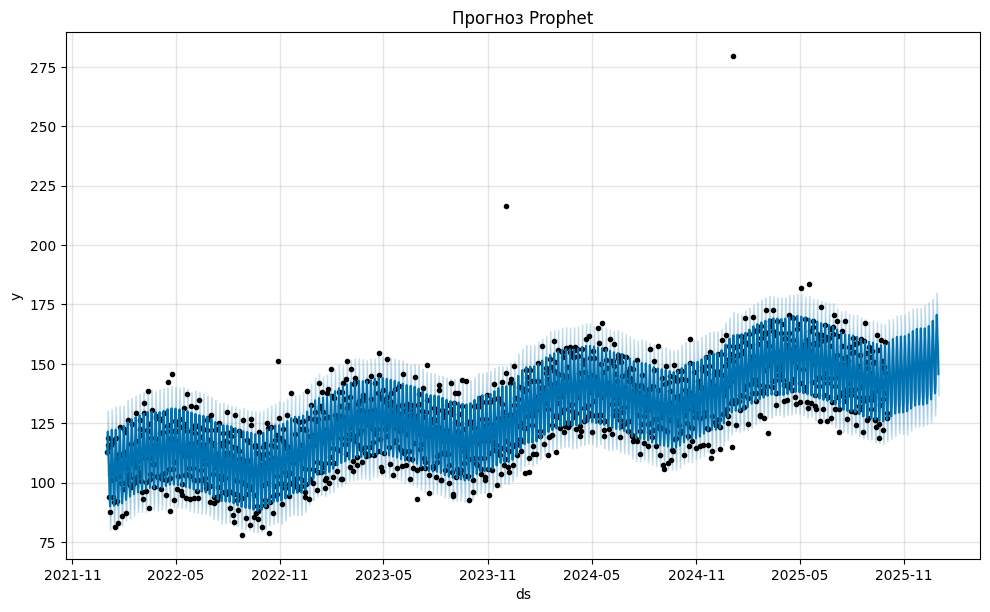

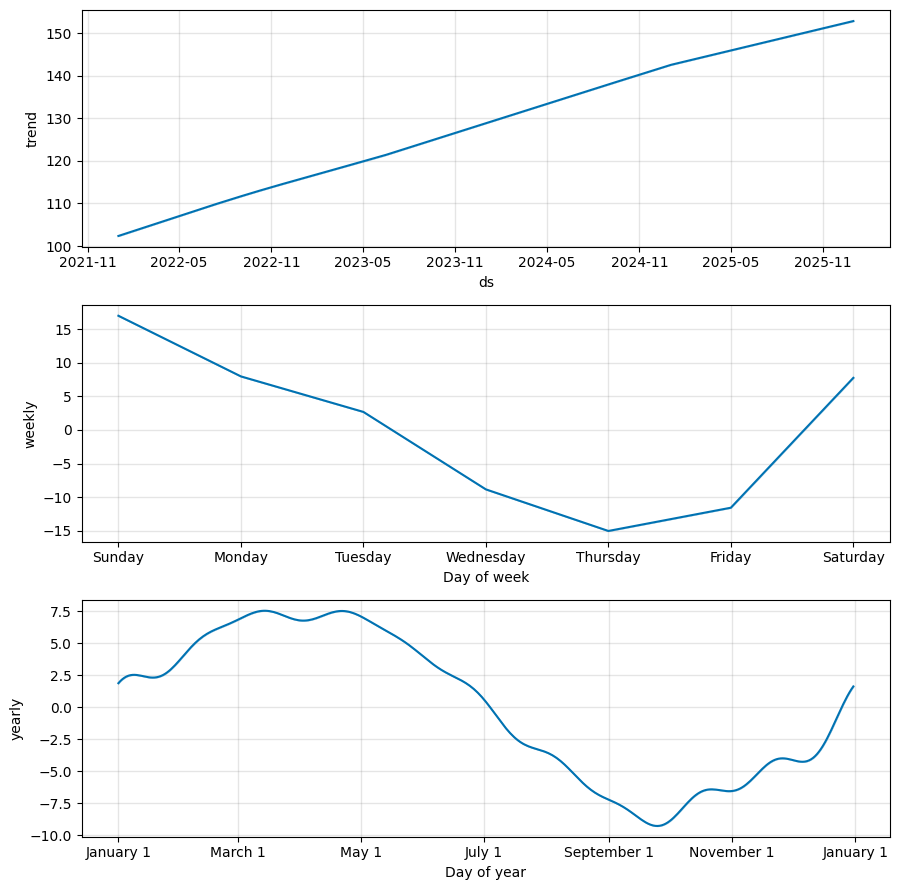

In [31]:
try:
    from prophet import Prophet
except ImportError:
    import sys
    if "google.colab" in sys.modules:
        %pip -q install prophet
        from prophet import Prophet
    else:
        Prophet = None
        print("Для Prophet у Colab виконайте: %pip install prophet")

prophet_metrics = None
if Prophet is not None:
    prophet_train = train.reset_index().rename(columns={"date": "ds", "sales": "y"})
    model_prophet = Prophet(weekly_seasonality=True, yearly_seasonality=True,
                            daily_seasonality=False, seasonality_mode="additive")
    model_prophet.fit(prophet_train)
    future = model_prophet.make_future_dataframe(periods=len(test), freq="D")
    forecast = model_prophet.predict(future)
    prophet_pred = forecast.set_index("ds").loc[test.index, "yhat"]
    prophet_metrics = evaluate(test["sales"], prophet_pred, train["sales"], 7)
    print("Порівняння MAE:")
    print("Prophet:", round(prophet_metrics["MAE"], 2))
    print("ETS:", round(ets_metrics["MAE"], 2))
    print("SARIMA:", round(sarima_metrics["MAE"], 2))

    model_prophet.plot(forecast)
    plt.title("Прогноз Prophet")
    plt.show()
    model_prophet.plot_components(forecast)
    plt.show()

## 12. Ознаки для машинного навчання

Для використання класичних ML-моделей часовий ряд перетворюють на табличний набір ознак.

Типові ознаки:

- лаги;
- ковзні середні;
- день тижня;
- місяць;
- день року;
- ознака вихідного дня.

**Критичний момент:** ковзні характеристики мають обчислюватися тільки за минулими значеннями. Саме тому перед `rolling()` використовується `shift(1)`.

In [52]:
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df = make_features(df["sales"]).dropna()
ml_df.head()

,y,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dayofweek,month,dayofyear,is_weekend
date,,,,,,,,,,,,,,
2022-01-29,111.082231,97.400770,85.764899,99.669338,112.207900,102.048594,112.980285,104.512145,104.134824,11.932523,5,1,29,1
2022-01-30,122.474286,111.082231,97.400770,85.764899,123.513016,118.574712,118.725005,104.351335,104.067036,11.818566,6,1,30,1
2022-01-31,113.086640,122.474286,111.082231,97.400770,107.038953,108.356362,115.930451,104.202945,104.200939,11.541145,0,1,31,0
2022-02-01,121.472125,113.086640,122.474286,111.082231,105.990140,109.993414,114.862459,105.066901,104.099374,12.005835,1,2,32,0
2022-02-02,100.017166,121.472125,113.086640,122.474286,99.669338,92.413005,94.078518,107.278613,104.335434,13.533155,2,2,33,0


In [35]:
ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

{'MAE': 6.4256724041518165,
 'RMSE': np.float64(7.708139982015866),
 'sMAPE_%': np.float64(4.411484230090363),
 'MASE': np.float64(0.9063953646912981)}

### Зауваження щодо попереднього прикладу

Цей приклад демонструє **табличне формування ознак** та оцінювання моделі. Для реального багатокрокового прогнозу потрібно чітко визначити, які ознаки будуть відомі у момент прогнозування.

Якщо для майбутніх дат лагова ознака використовує фактичне значення, яке на момент прогнозу ще невідоме, виникає **витік даних**.

Для багатокрокового прогнозування застосовують, зокрема:

- recursive strategy;
- direct strategy;
- multi-output strategy.

### Завдання 10. Feature engineering

Додайте щонайменше три нові ознаки:

- лаг 21;
- 14-денне ковзне середнє;
- номер тижня року.

Перенавчіть модель та порівняйте результат.

Після цього перевірте, чи всі створені ознаки могли бути відомими на момент формування прогнозу.

In [37]:
ml_extra = make_features(df["sales"])
ml_extra["lag_21"] = ml_extra["y"].shift(21)
ml_extra["roll_mean_14"] = ml_extra["y"].shift(1).rolling(14).mean()
ml_extra["weekofyear"] = ml_extra.index.isocalendar().week.astype(int)
ml_extra = ml_extra.dropna()

extra_train = ml_extra.loc[ml_extra.index < test.index.min()]
extra_test = ml_extra.loc[ml_extra.index >= test.index.min()]
X_extra_train = extra_train.drop(columns="y")
X_extra_test = extra_test.drop(columns="y")

gbr_extra = HistGradientBoostingRegressor(
    learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
    l2_regularization=1.0, random_state=42
)
gbr_extra.fit(X_extra_train, extra_train["y"])
ml_extra_pred = gbr_extra.predict(X_extra_test)
ml_extra_metrics = evaluate(extra_test["y"], ml_extra_pred, train["sales"], 7)
print(pd.DataFrame({"ML початкова": ml_metrics,
                    "ML з новими ознаками": ml_extra_metrics}).T.round(2))
print("Календарний тиждень відомий заздалегідь. Лаги та rolling")
print("вимагають минулих продажів. Як і в готовому прикладі, тут")
print("використані фактичні попередні значення test, тому це")
print("оцінювання з відомими лагами, не прогноз усіх 90 днів наперед.")

                       MAE  RMSE  sMAPE_%  MASE
ML початкова          6.43  7.71     4.41  0.91
ML з новими ознаками  5.99  7.54     4.10  0.84
Календарний тиждень відомий заздалегідь. Лаги та rolling
вимагають минулих продажів. Як і в готовому прикладі, тут
використані фактичні попередні значення test, тому це
оцінювання з відомими лагами, не прогноз усіх 90 днів наперед.


## 13. Порівняння моделей

Зведемо результати моделей у єдину таблицю.

In [38]:
comparison = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": ets_metrics,
    "SARIMA": sarima_metrics,
    "ML": ml_metrics
}).T

comparison.sort_values("MAE")

,MAE,RMSE,sMAPE_%,MASE
ML,6.425672,7.708140,4.411484,0.906395
Seasonal naive,7.734062,9.380056,5.276847,1.090955
SARIMA,7.746566,9.401756,5.302246,1.092719
ETS,13.114526,15.229021,9.149617,1.849915
Naive,22.039691,25.297086,15.570350,3.108885


### Завдання 11. Порівняння

Дайте письмову відповідь у Markdown-комірці:

1. Яка модель показала найменший MAE?
2. Чи перевершує вона seasonal naive?
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?
4. Яку модель Ви обрали б для практичного використання і чому?

**Ваша відповідь:**

За результатами порівняння найкращою виявилася ML-модель, яка показала найменшу MAE — приблизно 6,43. Це на 16,92 % краще, ніж seasonal naive, у якої MAE становить 7,73. Також ML-модель показала найкращі результати за всіма чотирма метриками. Але для прогнозування на 90 днів наперед я б обрав SARIMA, оскільки вона не використовує фактичні дані з тестового періоду. У ML та seasonal naive частково використовуються вже відомі значення, тому їхні результати можуть бути не зовсім точними для реального прогнозування.

## 14. Покрокова ретроспективна перевірка

Один train/test split може дати випадковий результат. Надійніший підхід — кілька разів імітувати ситуацію, коли модель навчається тільки на минулому та прогнозує наступний часовий відрізок.

Нижче реалізовано спрощений rolling-origin backtesting для seasonal naive.

In [39]:
def rolling_seasonal_naive_cv(series, initial=700, horizon=28, step=28, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=28,
    step=28,
    seasonality=7
)

cv_results

,train_end,test_start,test_end,MAE,RMSE
0,2023-12-01,2023-12-02,2023-12-29,11.726037,22.703319
1,2023-12-29,2023-12-30,2024-01-26,6.347953,7.977381
2,2024-01-26,2024-01-27,2024-02-23,6.816896,7.867398
3,2024-02-23,2024-02-24,2024-03-22,5.245028,6.584598
4,2024-03-22,2024-03-23,2024-04-19,7.455005,9.252134
5,2024-04-19,2024-04-20,2024-05-17,6.096014,7.548739
6,2024-05-17,2024-05-18,2024-06-14,7.319789,9.073672
7,2024-06-14,2024-06-15,2024-07-12,6.137219,7.365825
8,2024-07-12,2024-07-13,2024-08-09,5.629306,6.705414
9,2024-08-09,2024-08-10,2024-09-06,6.042439,7.485644


In [40]:
cv_results[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"])

,MAE,RMSE
mean,7.299416,9.797419
std,1.943769,5.694299
min,5.245028,6.584598
max,14.629295,34.184076


### Завдання 12. Backtesting

1. Змініть `horizon` з 28 на 14 днів.
2. Порівняйте середню MAE.
3. Побудуйте графік MAE для всіх fold.
4. Поясніть, що показує варіативність похибки між fold.

Середній MAE, горизонт 28 днів: 7.3
Середній MAE, горизонт 14 днів: 7.81


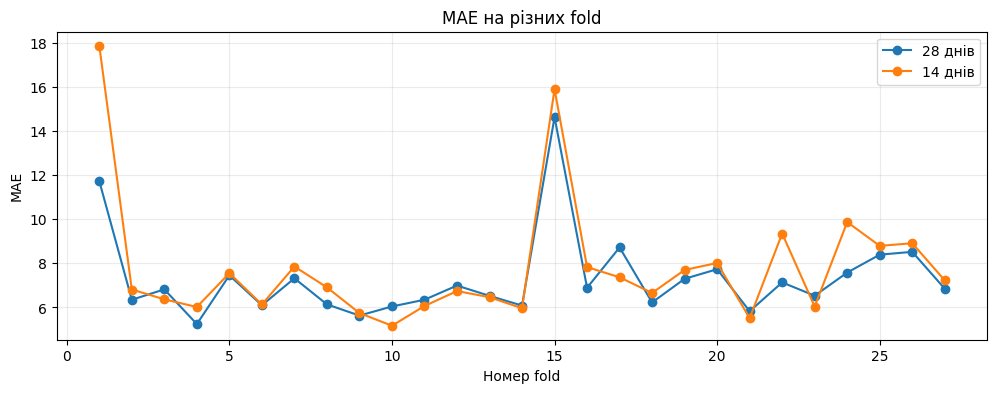

Коливання MAE між fold показують, що точність залежить від періоду.
Примітка: готова функція використовує попередні фактичні значення
усередині test_fold; це не повністю незалежний багатокроковий прогноз.


In [41]:
cv_14 = rolling_seasonal_naive_cv(
    df["sales"], initial=700, horizon=14, step=28, seasonality=7
)
print("Середній MAE, горизонт 28 днів:", round(cv_results["MAE"].mean(), 2))
print("Середній MAE, горизонт 14 днів:", round(cv_14["MAE"].mean(), 2))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(range(1, len(cv_results) + 1), cv_results["MAE"], marker="o", label="28 днів")
ax.plot(range(1, len(cv_14) + 1), cv_14["MAE"], marker="o", label="14 днів")
ax.set_title("MAE на різних fold")
ax.set_xlabel("Номер fold")
ax.set_ylabel("MAE")
ax.legend()
ax.grid(alpha=0.25)
plt.show()
print("Коливання MAE між fold показують, що точність залежить від періоду.")
print("Примітка: готова функція використовує попередні фактичні значення")
print("усередині test_fold; це не повністю незалежний багатокроковий прогноз.")

## 15. Додаткове завдання: прогнозні інтервали

Точковий прогноз показує одне найбільш очікуване значення. На практиці важливо також оцінювати невизначеність.

Використайте інтервал прогнозу SARIMA і визначте, яка частка фактичних значень тестової вибірки потрапила між нижньою та верхньою межами.

In [42]:
lower = sarima_ci.iloc[:, 0].to_numpy()
upper = sarima_ci.iloc[:, 1].to_numpy()
actual = test["sales"].to_numpy()
inside = (actual >= lower) & (actual <= upper)
print("У межах інтервалу:", inside.sum(), "із", len(inside))
print("Частка:", round(100 * inside.mean(), 2), "%")

У межах інтервалу: 87 із 90
Частка: 96.67 %


## 16. Підсумкове практичне завдання

Виконайте повний цикл прогнозування самостійно.

### Умова

Використайте часовий ряд `df["sales"]`.

### Необхідно

1. Провести первинний аналіз.
2. Перевірити пропуски та регулярність часової шкали.
3. Побудувати графік ряду.
4. Виконати STL-декомпозицію.
5. Виділити останні 60 днів як test.
6. Побудувати seasonal naive.
7. Побудувати одну статистичну модель: ETS або SARIMA.
8. Побудувати одну ML-модель.
9. Обчислити MAE, RMSE, sMAPE і MASE.
10. Порівняти моделі.
11. Побудувати графік найкращого прогнозу.
12. Сформулювати короткий висновок.

### Висновок має містити

- яка модель є найкращою;
- наскільки вона перевершує baseline;
- які закономірності виявлено в ряді;
- які обмеження має отриманий прогноз.

In [43]:
# 1. Первинний аналіз
print("Розмір:", df.shape)
print("Період:", df.index.min().date(), "—", df.index.max().date())
print(df["sales"].agg(["mean", "median", "std", "min", "max"]).round(2))

Розмір: (1461, 1)
Період: 2022-01-01 — 2025-12-31
mean      128.87
median    128.30
std        19.95
min        78.05
max       279.57
Name: sales, dtype: float64


In [44]:
# 2. Підготовка даних
print("Пропусків:", df["sales"].isna().sum())
print("Дублікати дат:", df.index.duplicated().sum())
print("Частота:", pd.infer_freq(df.index))
print("Дані вже підготовлені в розділі 3.")

Пропусків: 0
Дублікати дат: 0
Частота: D
Дані вже підготовлені в розділі 3.


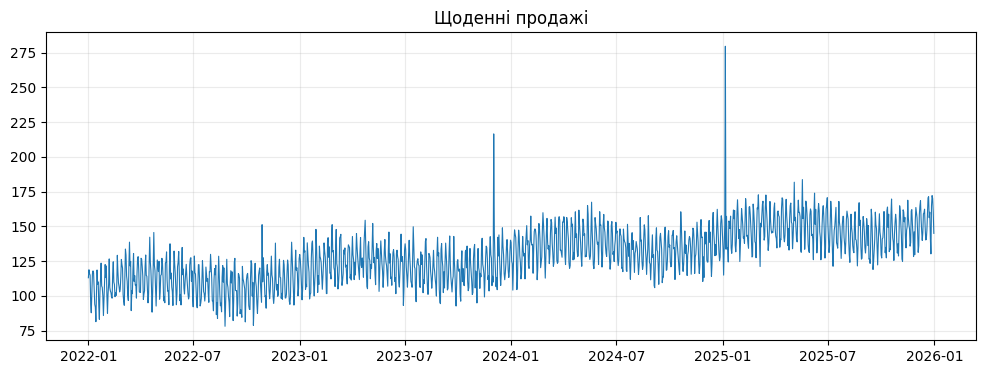

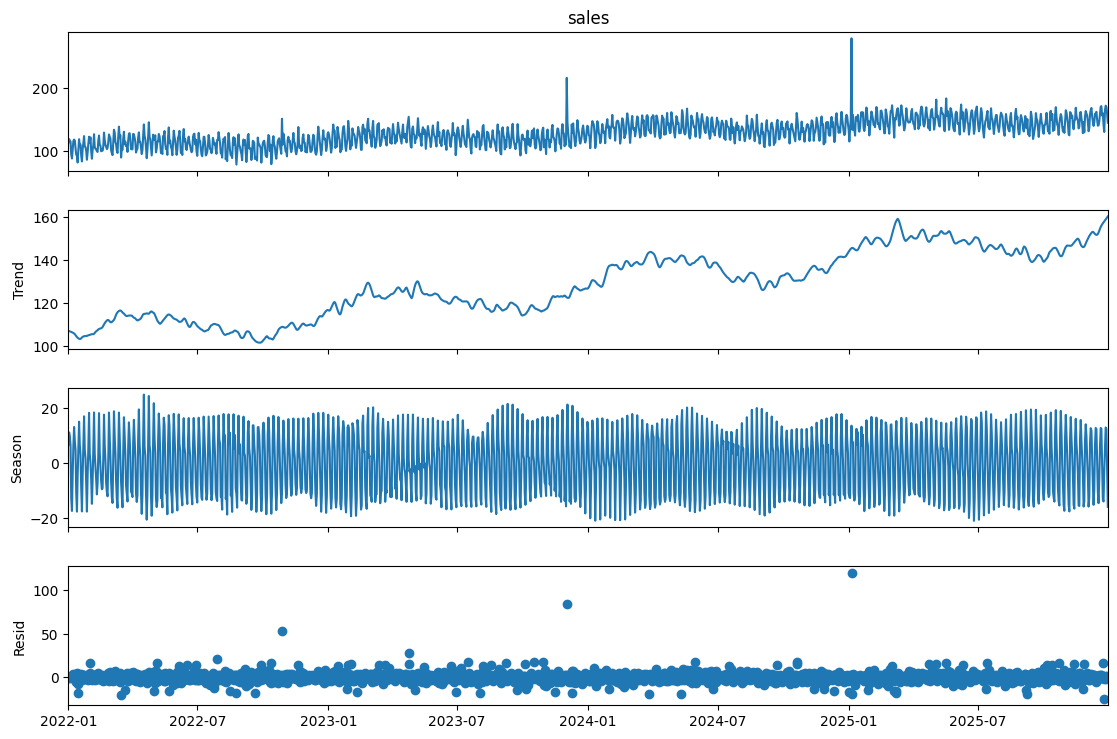

In [45]:
# 3. Візуалізація та STL
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df["sales"], linewidth=0.8)
ax.set_title("Щоденні продажі")
ax.grid(alpha=0.25)
plt.show()

final_stl = STL(df["sales"], period=7, robust=True).fit()
fig = final_stl.plot()
fig.set_size_inches(12, 8)
plt.show()

In [46]:
# 4. Train/test split
final_train = df.iloc[:-60].copy()
final_test = df.iloc[-60:].copy()
print("Train:", len(final_train), final_train.index.min().date(), "—", final_train.index.max().date())
print("Test:", len(final_test), final_test.index.min().date(), "—", final_test.index.max().date())

Train: 1401 2022-01-01 — 2025-11-01
Test: 60 2025-11-02 — 2025-12-31


In [47]:
# 5. Seasonal naive baseline
# Для прогнозу на 60 днів повторюємо лише останні 7 значень train.
last_week = final_train["sales"].iloc[-7:].to_numpy()
final_naive_pred = np.resize(last_week, len(final_test))
print(pd.Series(final_naive_pred, index=final_test.index).head(10).round(2))

date
2025-11-02    158.67
2025-11-03    154.38
2025-11-04    138.79
2025-11-05    130.73
2025-11-06    137.36
2025-11-07    128.64
2025-11-08    145.78
2025-11-09    158.67
2025-11-10    154.38
2025-11-11    138.79
dtype: float64


In [48]:
# 6. Статистична модель
final_ets_model = ExponentialSmoothing(
    final_train["sales"], trend="add", seasonal="add", seasonal_periods=7,
    initialization_method="estimated"
).fit()
final_ets_pred = final_ets_model.forecast(len(final_test))
print("ETS: прогноз на", len(final_ets_pred), "днів")

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


ETS: прогноз на 60 днів


In [49]:
# 7. ML-модель
# Використовуємо початкову функцію make_features без змін.
final_ml_df = make_features(final_train["sales"]).dropna()
final_ml_model = HistGradientBoostingRegressor(
    learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
    l2_regularization=1.0, random_state=42
)
final_ml_model.fit(final_ml_df.drop(columns="y"), final_ml_df["y"])

# Послідовно прогнозуємо дні, підставляючи попередні прогнози.
ml_history = final_train["sales"].copy()
final_ml_pred = []
for date in final_test.index:
    ml_history.loc[date] = np.nan
    features = make_features(ml_history).iloc[[-1]].drop(columns="y")
    value = final_ml_model.predict(features)[0]
    final_ml_pred.append(value)
    ml_history.loc[date] = value
print("ML: прогноз на", len(final_ml_pred), "днів")

ML: прогноз на 60 днів


In [50]:
# 8. Порівняння метрик
final_comparison = pd.DataFrame({
    "Seasonal naive": evaluate(final_test["sales"], final_naive_pred, final_train["sales"], 7),
    "ETS": evaluate(final_test["sales"], final_ets_pred, final_train["sales"], 7),
    "ML": evaluate(final_test["sales"], final_ml_pred, final_train["sales"], 7)
}).T.sort_values("MAE")
print(final_comparison.round(2))
print("Найкраща модель за MAE:", final_comparison.index[0])

                  MAE   RMSE  sMAPE_%  MASE
ETS              6.42   7.73     4.34  0.90
ML               7.62   9.22     5.16  1.07
Seasonal naive  10.16  11.99     6.92  1.43
Найкраща модель за MAE: ETS


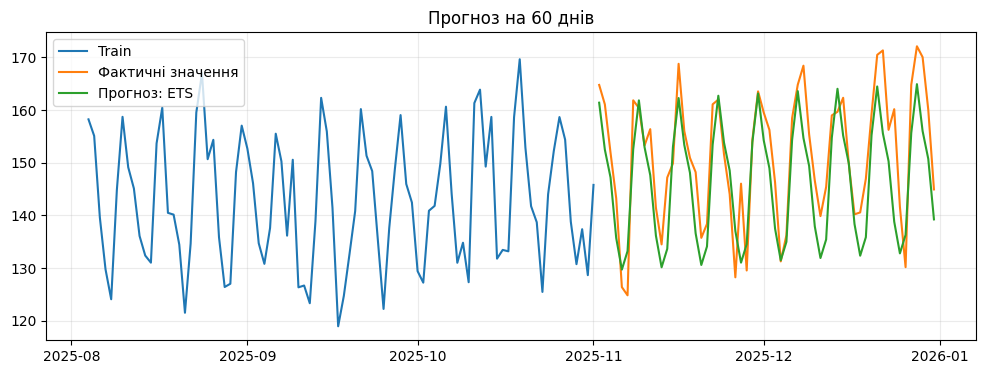

Найкраща модель: ETS
MAE baseline: 10.16
MAE найкращої: 6.42
Покращення: 36.85 %


In [51]:
# 9. Фінальний графік
final_predictions = {"Seasonal naive": final_naive_pred,
                     "ETS": final_ets_pred, "ML": final_ml_pred}
final_best_name = final_comparison.index[0]
final_best_pred = final_predictions[final_best_name]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(final_train.index[-90:], final_train["sales"].iloc[-90:], label="Train")
ax.plot(final_test.index, final_test["sales"], label="Фактичні значення")
ax.plot(final_test.index, final_best_pred, label="Прогноз: " + final_best_name)
ax.set_title("Прогноз на 60 днів")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

base_mae = final_comparison.loc["Seasonal naive", "MAE"]
best_mae = final_comparison.iloc[0]["MAE"]
print("Найкраща модель:", final_best_name)
print("MAE baseline:", round(base_mae, 2))
print("MAE найкращої:", round(best_mae, 2))
print("Покращення:", round(100 * (base_mae - best_mae) / base_mae, 2), "%")

### Підсумковий висновок

Напишіть 5–8 речень академічним стилем.

**Ваша відповідь:**

У підсумковій роботі я проаналізував щоденний часовий ряд продажів за 2022–2025 роки. За допомогою графіків і STL-декомпозиції було виявлено зростальний тренд, тижневу сезонність та окремі аномалії. Для перевірки якості останні 60 днів було відокремлено як тестову вибірку. Я побудував seasonal naive, ETS та ML-модель і порівняв їх за MAE, RMSE, sMAPE та MASE. Найкращою за MAE виявилася ETS із похибкою близько 6,42, тоді як seasonal naive мала MAE близько 10,16. Отже, використання ETS зменшило MAE приблизно на 36,85 % порівняно з базовою моделлю. Основними обмеженнями прогнозу залишаються випадковий шум, аномальні значення і можливі зміни характеру попиту в майбутньому.

## 17. Контрольні запитання

1. Чому не можна випадково перемішувати часовий ряд перед train/test split?
2. Для чого потрібна базова модель?
3. Чим naive відрізняється від seasonal naive?
4. Що показує MAE?
5. Чому MAPE може бути проблемною за наявності нульових значень?
6. Що означає параметр сезонності `s` у SARIMA?
7. Навіщо використовувати `shift(1)` перед обчисленням rolling-ознак?
8. Що таке витік даних у часових рядах?
9. Навіщо потрібен rolling-origin backtesting?
10. Чому найскладніша модель не обов'язково дає найкращий прогноз?